# Starter analysis

The basics: loading `results/timings.csv`, turning batch totals into per-operation costs,
summarizing replicates, and estimating a growth rate from a log-log fit.
It uses the rows from the worked `example` experiment (`make experiments ... ONLY=example`).

Make your own notebook(s) in `analysis/` for the real analysis; leave this one as a reference.

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = Path.cwd()

if not (root / "results" / "timings_annie_postfix.csv").exists():
    root = root.parent

df = pd.read_csv(root / "results" / "timings_annie_postfix.csv")

# Select the completed post-fix experiment sessions
e6 = df[
    (df["experiment"] == "E6") &
    (df["member"] == "annie") &
    (df["session_id"] == "303587bf004b")
].copy()

e7 = df[
    (df["experiment"] == "E7") &
    (df["member"] == "annie") &
    (df["session_id"] == "cd2a62150839")
].copy()

# Convert nanoseconds to milliseconds
e6["time_ms"] = e6["total_ns"] / 1_000_000
e7["time_ms"] = e7["total_ns"] / 1_000_000

# Extract B+ Tree order
e6["order"] = (
    e6["index_param"]
    .str.extract(r"order=(\d+)")
    .astype(int)
)

# Save updated figures to the report folder
fig_dir = root / "report" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

print("Post-fix E6 measurements:", len(e6))
print("Post-fix E7 measurements:", len(e7))



Post-fix E6 measurements: 225
Post-fix E7 measurements: 245


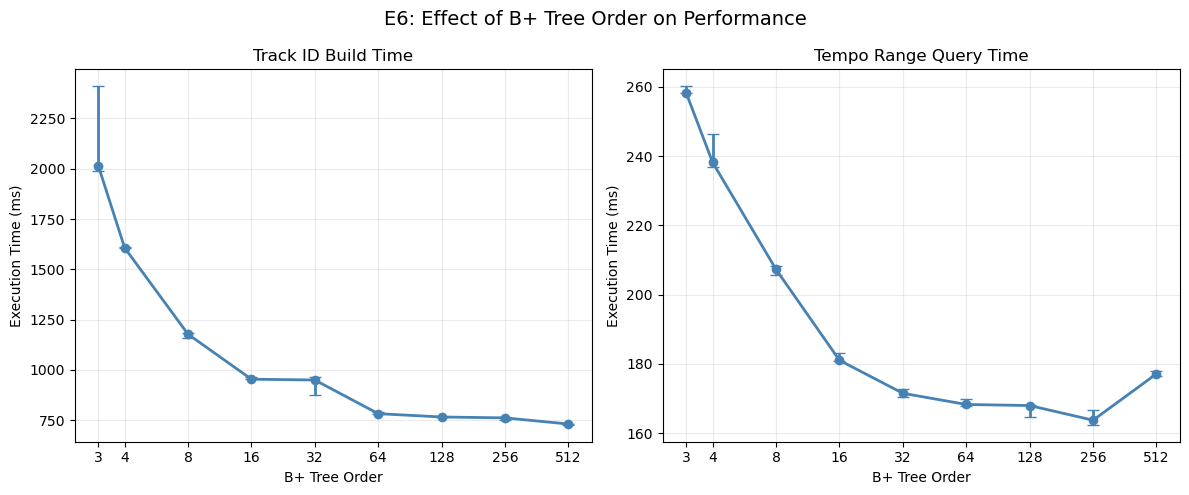

In [16]:

# Figure E6-A: B+ Tree build and range performance

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

settings = [
    ("track_id", "build", "Track ID Build Time"),
    ("tempo", "range", "Tempo Range Query Time")
]

for ax, (column, operation, title) in zip(axes, settings):

    subset = e6[
        (e6["key_column"] == column) &
        (e6["operation"] == operation)
    ]

    summary = (
        subset.groupby("order")["time_ms"]
        .agg(
            median="median",
            q1=lambda x: x.quantile(0.25),
            q3=lambda x: x.quantile(0.75)
        )
        .reset_index()
        .sort_values("order")
    )

    x = summary["order"].to_numpy()
    y = summary["median"].to_numpy()

    ax.errorbar(
        x, y,
        yerr=[
            y - summary["q1"].to_numpy(),
            summary["q3"].to_numpy() - y
        ],
        marker="o",
        capsize=4,
        linewidth=2,
        color="steelblue"
    )

    ax.set_xscale("log", base=2)
    ax.set_xticks(x)
    ax.set_xticklabels(x)
    ax.set_xlabel("B+ Tree Order")
    ax.set_ylabel("Execution Time (ms)")
    ax.set_title(title)
    ax.grid(alpha=0.25)

fig.suptitle("E6: Effect of B+ Tree Order on Performance", fontsize=14)
fig.tight_layout()


fig.savefig(
    fig_dir / "e6_build_range.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


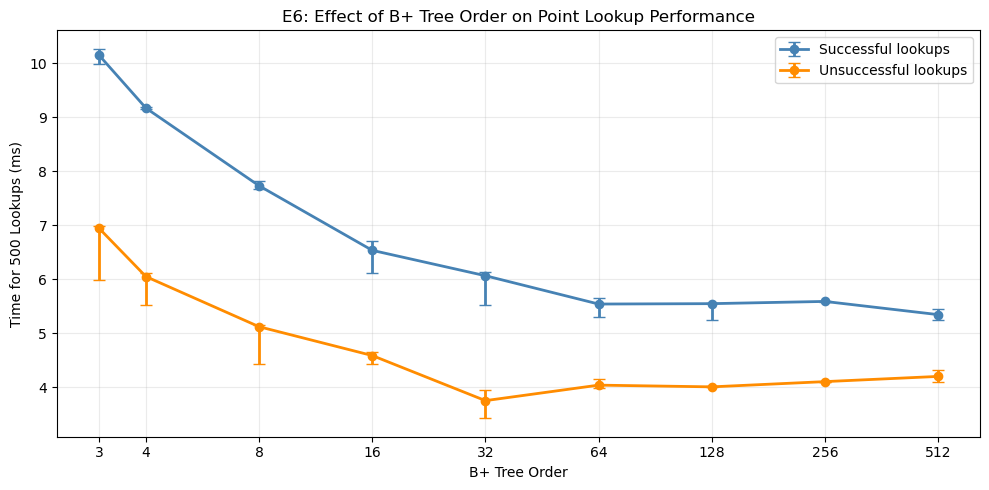

In [17]:

# Figure E6-B: Successful vs. unsuccessful point lookups

fig, ax = plt.subplots(figsize=(10, 5))

for operation, label, color in [
    ("point_hit", "Successful lookups", "steelblue"),
    ("point_miss", "Unsuccessful lookups", "darkorange")
]:
    subset = e6[
        (e6["key_column"] == "track_id") &
        (e6["operation"] == operation)
    ]

    summary = (
        subset.groupby("order")["time_ms"]
        .agg(
            median="median",
            q1=lambda x: x.quantile(0.25),
            q3=lambda x: x.quantile(0.75)
        )
        .reset_index()
        .sort_values("order")
    )

    x = summary["order"].to_numpy()
    y = summary["median"].to_numpy()

    ax.errorbar(
        x, y,
        yerr=[
            y - summary["q1"].to_numpy(),
            summary["q3"].to_numpy() - y
        ],
        marker="o",
        capsize=4,
        linewidth=2,
        color=color,
        label=label
    )

ax.set_xscale("log", base=2)
orders = [3, 4, 8, 16, 32, 64, 128, 256, 512]
ax.set_xticks(orders)
ax.set_xticklabels([str(order) for order in orders])

ax.set_xlabel("B+ Tree Order")
ax.set_ylabel("Time for 500 Lookups (ms)")
ax.set_title("E6: Effect of B+ Tree Order on Point Lookup Performance")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    fig_dir / "e6_point_lookups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


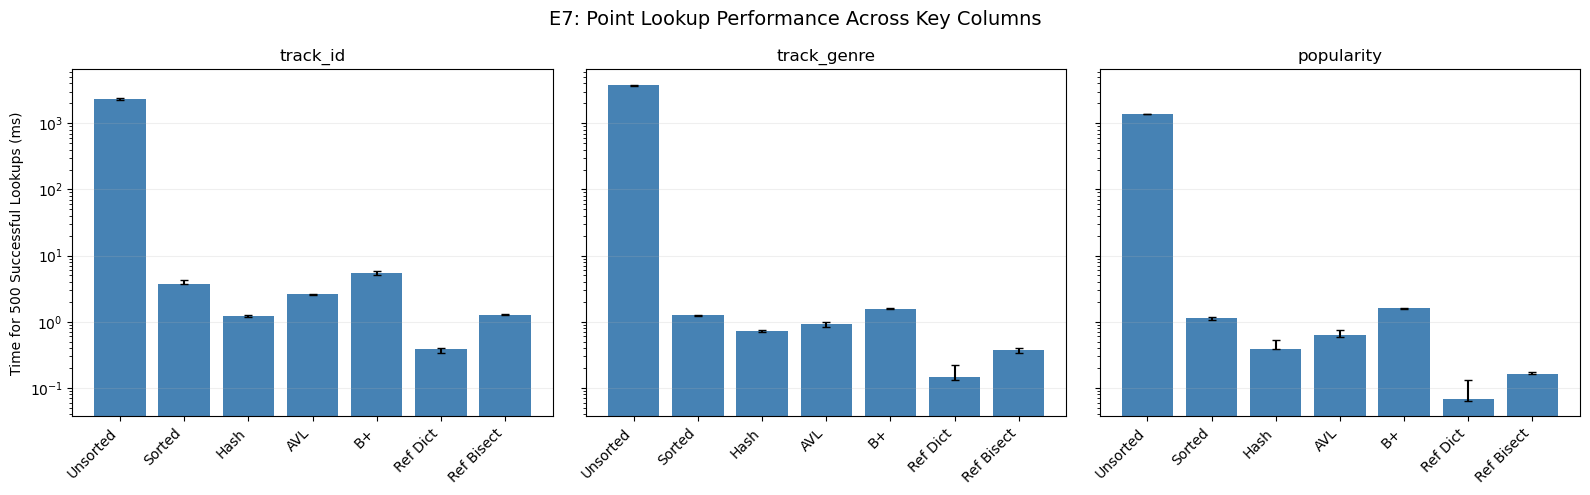

In [18]:

# Figure E7-A: Point lookup performance across key columns

indexes = [
    "unsorted_list", "sorted_list", "hash_table",
    "avl_tree", "bplus_tree", "ref_dict", "ref_bisect"
]

names = [
    "Unsorted", "Sorted", "Hash",
    "AVL", "B+", "Ref Dict", "Ref Bisect"
]

columns = ["track_id", "track_genre", "popularity"]

summary = (
    e7[e7["operation"] == "point_hit"]
    .groupby(["key_column", "index_type"])["time_ms"]
    .agg(
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, column in zip(axes, columns):

    data = (
        summary[summary["key_column"] == column]
        .set_index("index_type")
        .loc[indexes]
    )

    x = np.arange(len(indexes))
    y = data["median"].to_numpy()

    ax.bar(x, y, color="steelblue")

    ax.errorbar(
        x, y,
        yerr=[
            y - data["q1"].to_numpy(),
            data["q3"].to_numpy() - y
        ],
        fmt="none",
        ecolor="black",
        capsize=3
    )

    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=45, ha="right")
    ax.set_title(column)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Time for 500 Successful Lookups (ms)")

fig.suptitle(
    "E7: Point Lookup Performance Across Key Columns",
    fontsize=14
)

fig.tight_layout()

fig.savefig(
    fig_dir / "e7_point_lookups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


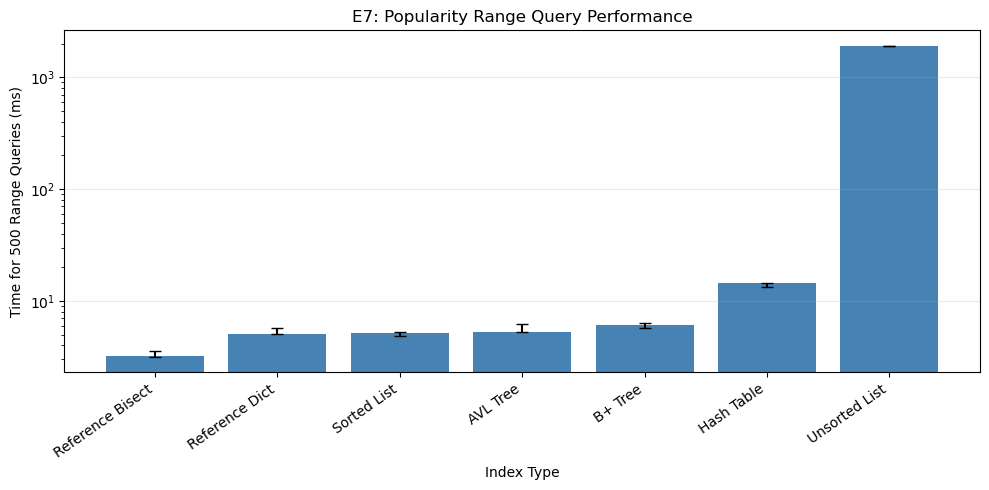

In [19]:

# Figure E7-B: Popularity range query performance

summary = (
    e7[
        (e7["key_column"] == "popularity") &
        (e7["operation"] == "range")
    ]
    .groupby("index_type")["time_ms"]
    .agg(
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
    .sort_values("median")
)

names = {
    "unsorted_list": "Unsorted List",
    "sorted_list": "Sorted List",
    "hash_table": "Hash Table",
    "avl_tree": "AVL Tree",
    "bplus_tree": "B+ Tree",
    "ref_dict": "Reference Dict",
    "ref_bisect": "Reference Bisect"
}

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(summary))
y = summary["median"].to_numpy()

ax.bar(x, y, color="steelblue")

ax.errorbar(
    x, y,
    yerr=[
        y - summary["q1"].to_numpy(),
        summary["q3"].to_numpy() - y
    ],
    fmt="none",
    ecolor="black",
    capsize=4
)

ax.set_xticks(x)
ax.set_xticklabels(
    [names[index] for index in summary["index_type"]],
    rotation=35,
    ha="right"
)

ax.set_yscale("log")
ax.set_xlabel("Index Type")
ax.set_ylabel("Time for 500 Range Queries (ms)")
ax.set_title("E7: Popularity Range Query Performance")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig(
    fig_dir / "e7_range_queries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [20]:

for name, data in [("E6", e6), ("E7", e7)]:
    print(f"\n{name} POST-FIX RESULTS")

    summary = (
        data.groupby(
            ["key_column", "operation", "index_type", "index_param"],
            dropna=False
        )["time_ms"]
        .median()
        .reset_index()
    )

    print(summary.to_string(index=False))



E6 POST-FIX RESULTS
key_column  operation index_type index_param     time_ms
     tempo      build bplus_tree   order=128  627.437427
     tempo      build bplus_tree    order=16  792.408172
     tempo      build bplus_tree   order=256  573.292371
     tempo      build bplus_tree     order=3 1590.547350
     tempo      build bplus_tree    order=32  720.828066
     tempo      build bplus_tree     order=4 1304.091827
     tempo      build bplus_tree   order=512  585.858682
     tempo      build bplus_tree    order=64  640.365050
     tempo      build bplus_tree     order=8  925.803114
     tempo      range bplus_tree   order=128  167.929892
     tempo      range bplus_tree    order=16  180.992537
     tempo      range bplus_tree   order=256  163.697512
     tempo      range bplus_tree     order=3  258.113631
     tempo      range bplus_tree    order=32  171.472059
     tempo      range bplus_tree     order=4  238.126534
     tempo      range bplus_tree   order=512  177.088866
     tempo

In [21]:

# E6: Summary of post-fix performance

e6_summary = (
    e6.groupby(["key_column", "operation", "order"])["time_ms"]
    .median()
    .reset_index()
)

e6_table = e6_summary.pivot_table(
    index="order",
    columns=["key_column", "operation"],
    values="time_ms"
)

print("E6 POST-FIX MEDIAN TIMES (ms)")
print(e6_table.round(3).to_string())



E6 POST-FIX MEDIAN TIMES (ms)
key_column     tempo           track_id                     
operation      build    range     build point_hit point_miss
order                                                       
3           1590.547  258.114  2015.261    10.148      6.946
4           1304.092  238.127  1607.304     9.168      6.050
8            925.803  207.234  1177.879     7.730      5.123
16           792.408  180.993   954.091     6.536      4.590
32           720.828  171.472   950.152     6.066      3.755
64           640.365  168.238   782.935     5.542      4.042
128          627.437  167.930   766.446     5.550      4.010
256          573.292  163.698   762.004     5.591      4.107
512          585.859  177.089   731.442     5.347      4.203


In [22]:

# E7: Summary of post-fix performance

e7_summary = (
    e7.groupby(["key_column", "operation", "index_type"])["time_ms"]
    .median()
    .reset_index()
)

e7_table = e7_summary.pivot_table(
    index="index_type",
    columns=["key_column", "operation"],
    values="time_ms"
)

print("E7 POST-FIX MEDIAN TIMES (ms)")
print(e7_table.round(3).to_string())



E7 POST-FIX MEDIAN TIMES (ms)
key_column    popularity                     track_genre            track_id          
operation          build point_hit     range       build point_hit     build point_hit
index_type                                                                            
avl_tree         636.310     0.629     5.320     712.960     0.924  2211.261     2.642
bplus_tree       356.725     1.630     6.076     307.155     1.565   982.398     5.525
hash_table       124.045     0.392    14.418     146.995     0.713   288.582     1.239
ref_bisect        51.771     0.162     3.228      66.063     0.378  1265.498     1.264
ref_dict          29.976     0.068     5.057      35.117     0.146    77.157     0.391
sorted_list      240.622     1.131     5.209     234.878     1.242  1824.048     3.747
unsorted_list     24.370  1373.059  1908.835      33.296  3746.254    28.140  2314.357
